# BAN 8101 Predictive Analytics
## Week 9: Deep Neural Networks for Autonomous Driving

### Big Question
**What changes when a neural network becomes deeper, and how do we train it without simply overfitting the training data?**

### Learning Objectives
After this class, you should be able to:
- Explain what makes a neural network deep
- Explain model capacity, underfitting, and overfitting
- Explain mini-batch training and batch size
- Explain how learning rate affects training
- Explain how dropout can reduce overfitting
- Compare multiple neural-network architectures using validation evidence
- Interpret training and validation loss curves
- Save and reload a trained PyTorch model
- Explain how a trained model will eventually connect to the self-driving simulator

# 1. From Week 8 to Week 9

Week 8 introduced the basic training cycle:

$$
\text{Input}\rightarrow\text{Forward Pass}\rightarrow\text{Prediction}\rightarrow\text{Loss}\rightarrow\text{Backpropagation}\rightarrow\text{Weight Update}
$$

Week 9 keeps that same cycle but increases network depth and training realism.

### Shallow example

$$
5\rightarrow16\rightarrow3
$$

### Deeper example

$$
5\rightarrow64\rightarrow32\rightarrow16\rightarrow3
$$

The deeper network has greater **capacity**, but greater capacity also creates more opportunity to overfit.

# 2. Model Capacity

Model capacity describes how flexible a model is.

More layers and neurons usually mean more trainable parameters. That can help the network learn complicated patterns, but it does not guarantee better performance on unseen data.

$$
\text{Too Little Capacity}\rightarrow\text{Underfitting}
$$

$$
\text{Too Much Capacity}\rightarrow\text{Overfitting Risk}
$$

The correct question is not **Which network is biggest?**

It is **Which network generalizes best?**

# 3. Create a Driving-State Dataset

In [35]:
# ---------------------------------------------------------------
# WHY THIS DATASET IS SYNTHETIC
#
# Week 9 is about understanding deep-neural-network behavior:
#   - depth
#   - model capacity
#   - mini-batches
#   - learning rate
#   - dropout
#   - overfitting
#
# If we introduced raw camera images here, students would also have to
# deal with image loading, image dimensions, image preprocessing, and
# convolutional networks. We intentionally postpone those topics.
#
# Each row below represents ONE driving moment.
# The variables are simplified teaching variables, not measurements
# from a calibrated physical vehicle.
# ---------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# RANDOM_STATE makes the generated dataset reproducible.
# Everyone running the notebook should receive the same lecture data.
RANDOM_STATE = 42

# default_rng is NumPy's modern random-number generator.
rng = np.random.default_rng(RANDOM_STATE)

# 6,000 observations are enough to train and compare several small DNNs,
# but still small enough to run quickly on an ordinary laptop.
n = 6000


# ===============================================================
# 1. ROAD CURVATURE
# ===============================================================
#
# We use a normalized synthetic scale from -1 to +1:
#
#   -1  -> strong left curve
#    0  -> approximately straight road
#   +1  -> strong right curve
#
# Why Uniform(-1, 1)?
# We want the training data to contain examples across the full range
# of left curves, straight-ish roads, and right curves instead of
# concentrating almost all observations around zero.
#
# This variable is dimensionless in this teaching example.
road_curvature = rng.uniform(
    -1.0,
    1.0,
    n
)


# ===============================================================
# 2. LATERAL OFFSET
# ===============================================================
#
# Interpretation:
#
#   negative -> vehicle is left of the desired lane center
#   zero     -> vehicle is centered
#   positive -> vehicle is right of the desired lane center
#
# Why Normal(mean=0, sd=0.35)?
# Most of the time we want the simulated vehicle to be reasonably close
# to the lane center, so values near 0 should be common.
#
# A normal distribution does that naturally:
# many small deviations, fewer large deviations.
#
# Why clip to [-1.2, +1.2]?
# A normal distribution can theoretically generate arbitrarily large
# values. Clipping prevents a few extreme synthetic observations from
# dominating the learning problem.
lateral_offset = np.clip(
    rng.normal(
        loc=0,
        scale=0.35,
        size=n
    ),
    -1.2,
    1.2
)


# ===============================================================
# 3. HEADING ERROR
# ===============================================================
#
# Heading error represents the difference between:
#   where the vehicle is pointing
# and
#   the desired road direction.
#
# Sign convention used here:
#
#   negative -> vehicle points somewhat left of the desired direction
#   positive -> vehicle points somewhat right of the desired direction
#
# Why Normal(mean=0, sd=6 degrees)?
# Most observations should have modest heading error, while a smaller
# number should represent larger recovery situations.
#
# Why clip to [-20, +20] degrees?
# We want meaningful variation without allowing extremely unrealistic
# synthetic heading errors.
heading_error = np.clip(
    rng.normal(
        loc=0,
        scale=6.0,
        size=n
    ),
    -20,
    20
)


# ===============================================================
# 4. SPEED
# ===============================================================
#
# Synthetic speed is generated from 5 to 25.
#
# Why not include 0?
# We want every row to represent a moving vehicle rather than a parked
# vehicle.
#
# Why Uniform(5, 25)?
# For this teaching exercise, we want broad coverage of lower and higher
# speeds rather than concentrating heavily around one speed.
#
# Think of this as a simplified speed index / nominal speed range,
# not as a carefully calibrated physical unit.
speed = rng.uniform(
    5,
    25,
    n
)


# ===============================================================
# 5. OBSTACLE DISTANCE
# ===============================================================
#
# This represents a simplified front-obstacle distance.
#
# Why 5 to 100?
# It creates a wide range from "relatively close" to "far away."
#
# IMPORTANT TEACHING DESIGN:
# obstacle_distance is intentionally NOT used in the steering-score
# equation below.
#
# Why?
# A real autonomous system may receive many sensor variables, but not
# every available variable must be useful for every target.
#
# Obstacle distance might matter strongly for braking or throttle,
# while contributing little to LEFT/STRAIGHT/RIGHT steering in this
# simplified example.
#
# This gives the DNN an "available but mostly irrelevant" predictor.
obstacle_distance = rng.uniform(
    5,
    100,
    n
)


# ===============================================================
# CREATE THE SYNTHETIC STEERING SCORE
# ===============================================================
#
# We first create a CONTINUOUS steering tendency.
#
# Positive score  -> tendency to steer Right
# Negative score  -> tendency to steer Left
# Score near 0    -> tendency to continue Straight
#
# This is NOT intended to be a real vehicle-control equation.
# The coefficients are chosen pedagogically so that:
#
#   1. road curvature is the strongest signal,
#   2. lane offset and heading error require corrective steering,
#   3. some effects are nonlinear,
#   4. some predictors interact,
#   5. random noise prevents perfect classification.
# ===============================================================

steering_score = (

    # -----------------------------------------------------------
    # MAIN EFFECT: road curvature
    #
    # +0.95 means curvature is the dominant steering signal.
    #
    # Positive curvature -> positive steering score -> Right
    # Negative curvature -> negative steering score -> Left
    # -----------------------------------------------------------
    0.95 * road_curvature

    # -----------------------------------------------------------
    # CORRECTION FOR LATERAL OFFSET
    #
    # The coefficient is negative.
    #
    # If the vehicle is RIGHT of center:
    #   lateral_offset > 0
    #   contribution becomes negative
    #   -> encourages a LEFT correction
    #
    # If the vehicle is LEFT of center:
    #   lateral_offset < 0
    #   contribution becomes positive
    #   -> encourages a RIGHT correction
    #
    # This mimics a simple "return toward lane center" idea.
    # -----------------------------------------------------------
    - 0.55 * lateral_offset

    # -----------------------------------------------------------
    # CORRECTION FOR HEADING ERROR
    #
    # Positive heading error means the vehicle is pointing too far
    # to the right relative to the desired road direction.
    #
    # A negative coefficient therefore encourages a left correction.
    #
    # The coefficient is small because heading_error is measured on
    # a much wider numerical scale than normalized curvature.
    # -----------------------------------------------------------
    - 0.025 * heading_error

    # -----------------------------------------------------------
    # NONLINEAR CURVATURE EFFECT
    #
    # Cubing preserves the sign:
    #   positive stays positive
    #   negative stays negative
    #
    # But it increases the relative importance of sharper curves.
    #
    # Example:
    #   0.2^3 = 0.008  -> very small extra effect
    #   0.9^3 = 0.729  -> much stronger extra effect
    #
    # This gives the DNN a genuinely nonlinear pattern to learn.
    # -----------------------------------------------------------
    + 0.35 * (road_curvature ** 3)

    # -----------------------------------------------------------
    # INTERACTION: SPEED x CURVATURE
    #
    # This term means the effect of road curvature changes depending
    # on speed.
    #
    # It is included mainly to teach interaction learning.
    #
    # IMPORTANT:
    # Do NOT interpret this as a physically correct steering controller.
    # In a real vehicle, control behavior at high speed would require
    # much more careful dynamics and safety design.
    # -----------------------------------------------------------
    + 0.015 * speed * road_curvature

    # -----------------------------------------------------------
    # INTERACTION: OFFSET x CURVATURE
    #
    # The corrective effect of lane position can depend on whether the
    # road itself is curving.
    #
    # This creates another pattern that cannot be represented by a
    # purely additive linear equation unless we manually create the
    # interaction feature.
    # -----------------------------------------------------------
    - 0.08 * lateral_offset * road_curvature

    # -----------------------------------------------------------
    # RANDOM NOISE
    #
    # Real prediction problems are rarely perfectly deterministic.
    #
    # Noise represents unobserved influences, measurement variation,
    # driver variation, and other information not included in X.
    #
    # Why sd = 0.14?
    # It is large enough to create some ambiguous cases and prediction
    # errors, but not so large that it overwhelms the meaningful signal.
    # -----------------------------------------------------------
    + rng.normal(
        loc=0,
        scale=0.14,
        size=n
    )
)


# ===============================================================
# CONVERT CONTINUOUS SCORE INTO THREE STEERING CLASSES
# ===============================================================
#
# We create a "dead zone" around zero:
#
# steering_score < -0.12  -> Left
# -0.12 to +0.12          -> Straight
# steering_score > +0.12  -> Right
#
# Why symmetric thresholds?
# Because the synthetic system treats left and right directions
# symmetrically.
#
# Why 0.12?
# It is a teaching choice selected to create a meaningful Straight
# region while still retaining substantial Left and Right examples.
#
# If the thresholds were much wider:
#   Straight would dominate.
#
# If they were very narrow:
#   almost every observation would become Left or Right.
#
# We therefore inspect class balance immediately after this cell.
LEFT_THRESHOLD = -0.12
RIGHT_THRESHOLD = 0.12

steering_class = np.where(
    steering_score < LEFT_THRESHOLD,
    "Left",
    np.where(
        steering_score > RIGHT_THRESHOLD,
        "Right",
        "Straight"
    )
)


# ===============================================================
# COMBINE EVERYTHING INTO ONE DATAFRAME
# ===============================================================

driving = pd.DataFrame({
    "road_curvature": road_curvature,
    "lateral_offset": lateral_offset,
    "heading_error": heading_error,
    "speed": speed,
    "obstacle_distance": obstacle_distance,
    "steering_class": steering_class
})

# Show the first few rows to verify that the dataset looks reasonable.
driving.head()

,road_curvature,lateral_offset,heading_error,speed,obstacle_distance,steering_class
0,0.547912,-0.362948,0.959589,11.464480,99.962125,Right
1,-0.122243,0.168922,5.357384,16.976954,43.968306,Left
2,0.717196,-0.212635,3.634865,9.151898,54.630415,Right
3,0.394736,-0.577173,-1.211692,5.851390,66.859244,Right
4,-0.811645,-0.100615,6.194357,18.849093,92.453030,Left


### Why These Synthetic Choices Are Reasonable for Teaching

The numerical ranges and coefficients above are **not intended as a real vehicle-control law**. They are chosen to create a learning problem with specific educational properties.

| Design choice | Teaching purpose |
|---|---|
| Curvature from -1 to +1 | Gives the model broad left/right road conditions |
| Offset centered near 0 | Represents a vehicle that is usually near lane center |
| Heading error centered near 0 | Represents mostly normal driving with some recovery situations |
| Speed from 5 to 25 | Allows the effect of curvature to vary with speed |
| Obstacle distance included but unused | Demonstrates that not every available sensor variable must predict every target |
| Cubic curvature term | Introduces nonlinearity |
| Interaction terms | Require the model to learn joint effects rather than only separate additive effects |
| Random noise | Prevents perfect deterministic classification |
| ±0.12 thresholds | Creates a Straight "dead zone" and turns a continuous score into a 3-class problem |

A useful question to ask is:

> **What would happen if we removed the nonlinear and interaction terms?**

The problem would become closer to a linear classification problem, and a deep neural network would have less opportunity to demonstrate an advantage over simpler models.

### How to Read This Output

Each row represents one driving state. The predictors describe the current vehicle/road condition, and `steering_class` is the outcome to predict.

Because these data are synthetic, focus on the **modeling workflow**, not on whether the numerical values perfectly represent a physical vehicle.

In [36]:
# Check class balance before modeling.
display(pd.DataFrame({
    'Count': driving['steering_class'].value_counts(),
    'Proportion': driving['steering_class'].value_counts(normalize=True).round(3)
}))

,Count,Proportion
steering_class,,
Left,2804,0.467
Right,2638,0.440
Straight,558,0.093


## What to Notice

The data contain nonlinear patterns such as:

$$
speed\times road\ curvature
$$

and:

$$
lateral\ offset\times road\ curvature
$$

A deeper neural network can potentially learn these interactions without us manually specifying every interaction feature.

# 4. Prepare Training, Validation, and Test Data

In [37]:
# ---------------------------------------------------------------
# PREPARE X AND y
# ---------------------------------------------------------------

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# These five columns are the predictors available to the model.
feature_names = [
    "road_curvature",
    "lateral_offset",
    "heading_error",
    "speed",
    "obstacle_distance"
]

# Convert the DataFrame predictors into a NumPy array.
# float32 is commonly used by PyTorch and uses less memory than float64.
X = driving[feature_names].to_numpy(
    dtype=np.float32
)

# Keep the original text labels temporarily.
y_text = driving["steering_class"].to_numpy()

# ---------------------------------------------------------------
# WHY CONVERT Left / Straight / Right TO 0 / 1 / 2?
#
# PyTorch's multiclass CrossEntropyLoss expects integer class IDs.
#
# The numbers do NOT mean that Right is "twice" Straight.
# They are simply category identifiers.
# ---------------------------------------------------------------
class_to_id = {
    "Left": 0,
    "Straight": 1,
    "Right": 2
}

y = np.array(
    [
        class_to_id[label]
        for label in y_text
    ],
    dtype=np.int64
)


# ===============================================================
# THREE-WAY DATA SPLIT
# ===============================================================
#
# We need three datasets because they serve different purposes:
#
# 1. TRAINING SET
#    Used by backpropagation to update weights.
#
# 2. VALIDATION SET
#    Used to compare architectures, dropout, learning rate, etc.
#
# 3. TEST SET
#    Kept untouched until model-development decisions are finished.
#
# If we repeatedly use the test set while choosing a model, it is no
# longer a truly independent final evaluation.
# ===============================================================

# Step 1:
# Hold out 20% of the FULL dataset as the final test set.
#
# test_size=0.20 means:
#   80% -> development data
#   20% -> final test data
#
# stratify=y keeps Left/Straight/Right proportions similar in both sets.
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Step 2:
# Split the remaining 80% development data.
#
# test_size=0.20 here means 20% OF THE DEVELOPMENT SET becomes validation.
#
# Overall proportions are therefore approximately:
#
#   Training   = 0.80 x 0.80 = 64%
#   Validation = 0.80 x 0.20 = 16%
#   Test       = 20%
#
# For n=6000, this is approximately:
#
#   Training   = 3840
#   Validation = 960
#   Test       = 1200
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (3840, 5)
Validation: (960, 5)
Test: (1200, 5)


### Why 64% / 16% / 20%?

There is nothing magical about these exact percentages. They are a practical compromise:

- **64% training** gives the DNN most of the observations for learning weights.
- **16% validation** is large enough to compare architectures and hyperparameters.
- **20% test** provides a substantial final holdout sample.

Other reasonable splits could be used. The important principle is that the **test set remains independent of model-development decisions**.

In [38]:
# ---------------------------------------------------------------
# WHY STANDARDIZE THE INPUTS?
#
# Our variables use very different numerical ranges:
#
# road_curvature    ~ -1 to +1
# lateral_offset    ~ -1.2 to +1.2
# heading_error     ~ -20 to +20
# speed             ~ 5 to 25
# obstacle_distance ~ 5 to 100
#
# Neural networks are trained using gradients.
# If one variable has much larger numerical values than another,
# optimization can become less efficient.
#
# StandardScaler transforms each predictor approximately to:
#
#     mean = 0
#     standard deviation = 1
#
# Formula:
#
#     z = (x - mean) / standard deviation
#
# ---------------------------------------------------------------

scaler = StandardScaler()

# IMPORTANT:
# fit_transform() is used ONLY on the training data.
#
# "fit" learns the training means and standard deviations.
# "transform" applies those learned values.
#
# We must NOT fit the scaler on validation or test data because that
# would allow information from unseen data to influence preprocessing.
X_train_scaled = scaler.fit_transform(
    X_train
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

print("Training means after scaling:")
print(
    np.round(
        X_train_scaled.mean(axis=0),
        3
    )
)

print("\nTraining standard deviations after scaling:")
print(
    np.round(
        X_train_scaled.std(axis=0),
        3
    )
)

Training means after scaling:
[-0. -0. -0.  0. -0.]

Training standard deviations after scaling:
[1. 1. 1. 1. 1.]


# 5. Mini-Batch Training

In Week 8, we could train using the entire training set at once.

Deep neural networks are commonly trained using **mini-batches**.

Instead of one update from the full dataset, the network may update after every 64 observations.

The number of observations used for one update is the **batch size**.

In [39]:
import torch
import torch.nn as nn
from torch.utils.data import (
    TensorDataset,
    DataLoader
)

# ---------------------------------------------------------------
# CONVERT NUMPY ARRAYS TO PYTORCH TENSORS
# ---------------------------------------------------------------
#
# Think of a tensor as a NumPy-like numerical array that PyTorch can use
# for automatic differentiation and neural-network training.
#
# Predictor tensors use float32.
# Classification targets use integer type torch.long.
# ---------------------------------------------------------------

X_train_t = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_val_t = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

X_test_t = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_t = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_t = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_t = torch.tensor(
    y_test,
    dtype=torch.long
)


# ---------------------------------------------------------------
# TensorDataset PAIRS EACH X ROW WITH ITS y LABEL
# ---------------------------------------------------------------
#
# Observation 1:
#   five driving inputs -> one steering class
#
# Observation 2:
#   five driving inputs -> one steering class
#
# and so on.
# ---------------------------------------------------------------

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)


# ===============================================================
# WHY BATCH_SIZE = 64?
# ===============================================================
#
# Instead of using all 3,840 training observations for one giant update,
# we let the model learn from smaller groups.
#
# Batch size 64 is a common practical teaching choice because:
#
#   - it is small enough to create many weight updates,
#   - it is large enough to give each update a useful sample,
#   - it runs efficiently on ordinary CPUs/GPUs,
#   - it is easy to reason about in class.
#
# It is NOT universally optimal.
#
# With ~3840 training observations:
#
#     3840 / 64 = 60 mini-batches per epoch
#
# Therefore the optimizer updates the weights about 60 times each epoch.
# ===============================================================

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,

    # shuffle=True changes observation order each epoch.
    #
    # Why?
    # We do not want the model to learn artifacts from a fixed row order.
    shuffle=True
)

print(
    "Training observations:",
    len(train_dataset)
)

print(
    "Mini-batches per epoch:",
    len(train_loader)
)

Training observations: 3840
Mini-batches per epoch: 60


### Why Not Use Batch Size 1 or the Entire Dataset?

At the extremes:

**Batch size = 1**

- very frequent updates,
- highly noisy gradients,
- potentially slow computation.

**Batch size = entire training set**

- only one update per epoch,
- stable gradient estimate,
- less stochasticity,
- less representative of how modern DNNs are commonly trained.

A mini-batch such as **64** provides a useful middle ground for this class.

### How to Interpret Mini-Batches

If the notebook reports about 60 mini-batches per epoch, the optimizer performs about 60 weight updates during each epoch.

That is one major difference from full-batch training: learning happens through many smaller updates.

## Check Your Understanding

If there are 3,840 training observations and the batch size is 64:

$$
3840/64=60
$$

The optimizer updates the network about 60 times during one epoch.

# 6. Compare Three Network Architectures

### Small

$$
5\rightarrow8\rightarrow3
$$

### Medium

$$
5\rightarrow32\rightarrow16\rightarrow3
$$

### Deep

$$
5\rightarrow64\rightarrow32\rightarrow16\rightarrow3
$$

In [40]:
# ===============================================================
# WHY COMPARE THREE ARCHITECTURES?
# ===============================================================
#
# We want students to see that "deeper" is not automatically "better."
#
# All three networks receive:
#   5 input variables
#
# All three networks output:
#   3 class logits: Left / Straight / Right
#
# The only major difference is model capacity.
# ===============================================================


# ---------------------------------------------------------------
# SMALL NETWORK
#
# Architecture:
#
# 5 inputs -> 8 hidden neurons -> 3 output logits
#
# Purpose:
# Provide a low-capacity baseline.
# It may be enough if the prediction relationship is fairly simple.
# ---------------------------------------------------------------

class SmallNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            # 5 predictors enter the first layer.
            # The layer creates 8 learned hidden values.
            nn.Linear(5, 8),

            # ReLU introduces nonlinearity.
            nn.ReLU(),

            # Convert 8 hidden values into 3 class scores.
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.network(x)


# ---------------------------------------------------------------
# MEDIUM NETWORK
#
# Architecture:
#
# 5 -> 32 -> 16 -> 3
#
# Why choose 32 and 16?
# They provide clearly more capacity than SmallNet while remaining
# computationally inexpensive for an in-class exercise.
#
# The narrowing pattern 32 -> 16 is also easy for students to visualize:
# the model first creates a richer representation, then compresses it.
# ---------------------------------------------------------------

class MediumNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(5, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)


# ---------------------------------------------------------------
# DEEP NETWORK
#
# Architecture:
#
# 5 -> 64 -> 32 -> 16 -> 3
#
# Why this architecture?
# It deliberately has more hidden layers and parameters so we can ask:
#
#   Does additional capacity improve validation performance?
#   Or does it mostly improve training fit?
#
# 64/32/16 are pedagogical choices, not a claim of optimality.
# ---------------------------------------------------------------

class DeepNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)

### Why Use 8, 32, 16, and 64 Neurons?

These numbers are chosen to create visibly different levels of capacity while keeping computation small.

They are **not optimal values discovered through tuning**.

The purpose of the experiment is to ask:

> Does increasing capacity from Small → Medium → Deep improve validation performance enough to justify the added complexity?

In a real modeling project, architecture would be tuned systematically using validation results.

# 7. Count Trainable Parameters

In [41]:
# ---------------------------------------------------------------
# TRAINABLE PARAMETER COUNT
#
# Every learned weight and bias is a parameter.
# More parameters generally mean more capacity and more computation.
# ---------------------------------------------------------------

def count_parameters(model):
    # Count trainable weights and biases.
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

parameter_table = pd.DataFrame({
    'Model': ['Small', 'Medium', 'Deep'],
    'Trainable Parameters': [
        count_parameters(SmallNet()),
        count_parameters(MediumNet()),
        count_parameters(DeepNet())
    ]
})

parameter_table

# RESULT INTERPRETATION:
# Use parameter count as a complexity measure, not as a quality score.


,Model,Trainable Parameters
0,Small,75
1,Medium,771
2,Deep,3043


## Pause and Think

More parameters mean more flexibility, but not automatically better generalization.

The larger model must earn its complexity through validation performance or another meaningful advantage.

# 8. Learning Rate

The learning rate controls the size of the parameter updates:

$$
w_{new}=w_{old}-\eta\frac{\partial L}{\partial w}
$$

- Too large: training may become unstable.
- Too small: training may improve very slowly.

# 9. Reusable Mini-Batch Training Function

In [42]:
def train_model(
    model,
    train_loader,
    X_val_t,
    y_val_t,
    epochs=80,
    learning_rate=0.01
):
    """
    Train one neural network using mini-batches.

    Returns
    -------
    train_history : list
        Average training loss after each epoch.

    val_history : list
        Validation loss after each epoch.
    """

    # -----------------------------------------------------------
    # LOSS FUNCTION: CrossEntropyLoss
    #
    # Why?
    # We have a multiclass classification problem:
    #
    #   Left / Straight / Right
    #
    # CrossEntropyLoss compares the model's three class logits with the
    # correct integer class ID.
    #
    # We do NOT apply softmax manually before this loss function because
    # PyTorch handles the required calculation internally.
    # -----------------------------------------------------------
    criterion = nn.CrossEntropyLoss()


    # -----------------------------------------------------------
    # OPTIMIZER: Adam
    #
    # Why Adam?
    # Adam is a widely used default optimizer that adapts parameter
    # updates during training and is convenient for introductory DNN work.
    #
    # It is not always the best optimizer for every problem.
    # -----------------------------------------------------------
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )


    train_history = []
    val_history = []


    # ===========================================================
    # EPOCH LOOP
    #
    # One epoch = one complete pass through all training observations.
    #
    # Why 80 epochs?
    # This is long enough for these small networks to show meaningful
    # learning behavior while still running quickly in class.
    #
    # It is a teaching choice, not a universal rule.
    # ===========================================================
    for epoch in range(epochs):


        # =======================================================
        # TRAINING PHASE
        # =======================================================

        # model.train() tells PyTorch we are training.
        # This matters especially for layers such as Dropout.
        model.train()

        total_loss = 0.0
        total_n = 0


        # -------------------------------------------------------
        # MINI-BATCH LOOP
        #
        # The DataLoader gives us one group of 64 observations at a time.
        # -------------------------------------------------------
        for X_batch, y_batch in train_loader:


            # 1. CLEAR OLD GRADIENTS
            #
            # PyTorch accumulates gradients by default.
            # We must clear the previous batch's gradients before
            # calculating new ones.
            optimizer.zero_grad()


            # 2. FORWARD PASS
            #
            # Send the 64 observations through the network.
            #
            # Output shape:
            #   64 rows x 3 class logits
            logits = model(
                X_batch
            )


            # 3. CALCULATE LOSS
            #
            # Compare predicted logits with the true class labels.
            loss = criterion(
                logits,
                y_batch
            )


            # 4. BACKPROPAGATION
            #
            # Calculate how each trainable parameter contributed to loss.
            loss.backward()


            # 5. UPDATE PARAMETERS
            #
            # Adam uses the gradients to modify weights and biases.
            optimizer.step()


            # ---------------------------------------------------
            # ACCUMULATE TRAINING LOSS
            #
            # loss.item() is the average loss for this mini-batch.
            #
            # Multiplying by batch_n converts it back to a total-like
            # quantity so we can calculate the correct average across
            # the entire epoch, including a possibly smaller last batch.
            # ---------------------------------------------------
            batch_n = X_batch.shape[0]

            total_loss += (
                loss.item()
                * batch_n
            )

            total_n += batch_n


        # Average training loss for the complete epoch.
        epoch_train_loss = (
            total_loss
            / total_n
        )

        train_history.append(
            epoch_train_loss
        )


        # =======================================================
        # VALIDATION PHASE
        # =======================================================

        # model.eval() tells PyTorch we are evaluating rather than training.
        # Dropout is disabled in this mode.
        model.eval()


        # no_grad() means we do not need gradients because we are not
        # updating parameters on validation data.
        with torch.no_grad():

            # Run ALL validation observations through the network.
            val_logits = model(
                X_val_t
            )

            # Measure validation loss.
            val_loss = criterion(
                val_logits,
                y_val_t
            )


        val_history.append(
            val_loss.item()
        )


    return (
        train_history,
        val_history
    )

# 10. Train All Three Architectures

In [43]:
# ===============================================================
# TRAINING SETTINGS
# ===============================================================

# Why 80 epochs?
# Enough repetitions for these small networks to learn and show
# differences in validation behavior without making class runtime long.
EPOCHS = 80

# Why learning rate = 0.01?
#
# 0.01 is intentionally used as a reasonable starting point for Adam
# in this small standardized-data example.
#
# Later in the notebook we compare:
#
#   0.1
#   0.01
#   0.001
#
# so students can SEE why learning rate matters.
LEARNING_RATE = 0.01


# ---------------------------------------------------------------
# WHY RESET torch.manual_seed BEFORE EACH MODEL?
#
# Neural-network weights start from random initial values.
#
# If each architecture starts from unrelated randomness, part of the
# performance difference could simply come from initialization.
#
# Resetting the seed improves reproducibility and makes the classroom
# comparison more controlled.
#
# Note:
# the architectures have different shapes, so their actual parameter
# arrays are not identical; the seed simply makes initialization
# reproducible.
# ---------------------------------------------------------------

torch.manual_seed(
    RANDOM_STATE
)
small_model = SmallNet()

torch.manual_seed(
    RANDOM_STATE
)
medium_model = MediumNet()

torch.manual_seed(
    RANDOM_STATE
)
deep_model = DeepNet()


# ---------------------------------------------------------------
# TRAIN ALL THREE MODELS WITH THE SAME SETTINGS
# ---------------------------------------------------------------

small_train_loss, small_val_loss = train_model(
    small_model,
    train_loader,
    X_val_t,
    y_val_t,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)

medium_train_loss, medium_val_loss = train_model(
    medium_model,
    train_loader,
    X_val_t,
    y_val_t,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)

deep_train_loss, deep_val_loss = train_model(
    deep_model,
    train_loader,
    X_val_t,
    y_val_t,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)

print(
    "Training complete."
)

Training complete.


### Important Distinction: Hyperparameters vs. Learned Parameters

The network contains two different kinds of quantities.

**Learned parameters**

- weights
- biases

These are estimated automatically through backpropagation.

**Hyperparameters**

- number of hidden layers
- neurons per layer
- batch size
- learning rate
- number of epochs
- dropout rate

These are choices made by the analyst before or during model development.

Much of Week 9 is about learning how to make and evaluate those choices.

# 11. Compare Validation Loss

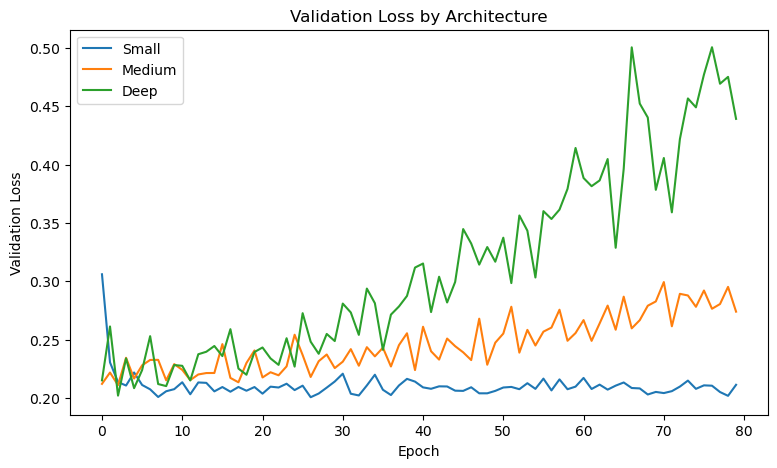

In [44]:
plt.figure(figsize=(9,5))
plt.plot(small_val_loss, label='Small')
plt.plot(medium_val_loss, label='Medium')
plt.plot(deep_val_loss, label='Deep')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Validation Loss by Architecture')
plt.legend()
plt.show()

# HOW TO READ THIS PLOT:
# - Lower validation loss is generally better.
# - A curve that falls and then rises may indicate overfitting.
# - A consistently high curve may indicate underfitting.


### How to Read the Validation-Loss Curves

Look for:

- which model reaches the lowest validation loss,
- whether any curve begins increasing after initially improving,
- whether the deeper network actually provides a meaningful advantage.

A model can fit the training data extremely well and still generalize poorly.

## What to Notice

The best training fit is not necessarily the best validation fit.

The central question is:

> **Which architecture generalizes best to unseen data?**

# 12. Compare Validation Accuracy and Macro F1

In [45]:
# ---------------------------------------------------------------
# TURN MODEL OUTPUTS INTO FAMILIAR METRICS
#
# Accuracy = overall fraction classified correctly.
# Macro F1 = gives Left, Straight, and Right equal importance.
# ---------------------------------------------------------------

def evaluate_model(model, X_tensor, y_true):
    model.eval()
    with torch.no_grad():
        logits = model(X_tensor)
        pred = torch.argmax(logits, dim=1).numpy()

    accuracy = accuracy_score(y_true, pred)
    macro_f1 = f1_score(y_true, pred, average='macro')
    return accuracy, macro_f1, pred

results = []
predictions = {}

for name, model in {
    'Small': small_model,
    'Medium': medium_model,
    'Deep': deep_model
}.items():
    acc, f1, pred = evaluate_model(model, X_val_t, y_val)
    predictions[name] = pred
    results.append({
        'Model': name,
        'Validation Accuracy': acc,
        'Validation Macro F1': f1,
        'Parameters': count_parameters(model)
    })

comparison = pd.DataFrame(results)
comparison.round(3)

# RESULT INTERPRETATION:
# Compare validation metrics together with parameter count.
# A tiny gain from a much larger network may not justify the complexity.


,Model,Validation Accuracy,Validation Macro F1,Parameters
0,Small,0.909,0.801,75
1,Medium,0.897,0.783,771
2,Deep,0.886,0.787,3043


### Interpreting the Architecture Comparison

Use the validation metrics together with model size.

For example, if the Medium and Deep networks have nearly identical Macro F1 but the Medium model uses far fewer parameters, the Medium network may be the more defensible choice.

If the Deep network produces a substantial validation improvement, the additional complexity may be justified.

# 13. Underfitting vs. Overfitting

### Underfitting
Training and validation performance are both weak.

### Good Generalization
Training and validation performance are both strong.

### Overfitting
Training performance keeps improving while validation performance stops improving or becomes worse.

# 14. Dropout

Dropout is a regularization technique. During training, it randomly deactivates some hidden-unit outputs.

The goal is to reduce over-reliance on individual neurons.

Dropout is active during `model.train()` and disabled during `model.eval()`.

In [46]:
# ===============================================================
# DEEP NETWORK WITH DROPOUT
# ===============================================================
#
# Dropout randomly sets some hidden activations to zero DURING TRAINING.
#
# Why p = 0.20?
#
# p=0.20 means approximately 20% of the selected activations are dropped
# on a training pass.
#
# 20% is a moderate teaching value:
#
#   - large enough for students to observe the idea,
#   - not so aggressive that most information is removed.
#
# It is NOT a universal best dropout rate.
#
# In practice, dropout values such as 0.1, 0.2, 0.3, or 0.5 might be
# tested depending on the architecture and amount of overfitting.
# ===============================================================

class DeepNetWithDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(5, 64),
            nn.ReLU(),

            # Randomly drop about 20% of these hidden activations
            # during training.
            nn.Dropout(
                p=0.20
            ),

            nn.Linear(64, 32),
            nn.ReLU(),

            # Apply dropout again in the next hidden representation.
            nn.Dropout(
                p=0.20
            ),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)


# Reproducible weight initialization.
torch.manual_seed(
    RANDOM_STATE
)

dropout_model = DeepNetWithDropout()


# Train using the SAME epoch count and learning rate as the original
# DeepNet so the comparison focuses mainly on dropout.
drop_train_loss, drop_val_loss = train_model(
    dropout_model,
    train_loader,
    X_val_t,
    y_val_t,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)


# Evaluate on validation data.
drop_acc, drop_f1, drop_pred = evaluate_model(
    dropout_model,
    X_val_t,
    y_val
)

print(
    "Dropout Accuracy:",
    round(drop_acc, 3)
)

print(
    "Dropout Macro F1:",
    round(drop_f1, 3)
)

Dropout Accuracy: 0.903
Dropout Macro F1: 0.774


### Why Dropout Can Help

A flexible network may discover combinations of hidden units that fit the training set extremely well.

Dropout makes training more difficult on purpose: the network cannot assume that every hidden activation will always be available.

That encourages the network to distribute useful information across multiple pathways.

However, if the original network is **not overfitting**, dropout can actually hurt performance. Regularization is a tool, not an automatic improvement.

### Interpreting Dropout

Do not assume dropout should always raise accuracy.

Its purpose is to improve generalization by reducing over-reliance on particular hidden units. Compare validation metrics and loss curves before deciding whether dropout helped.

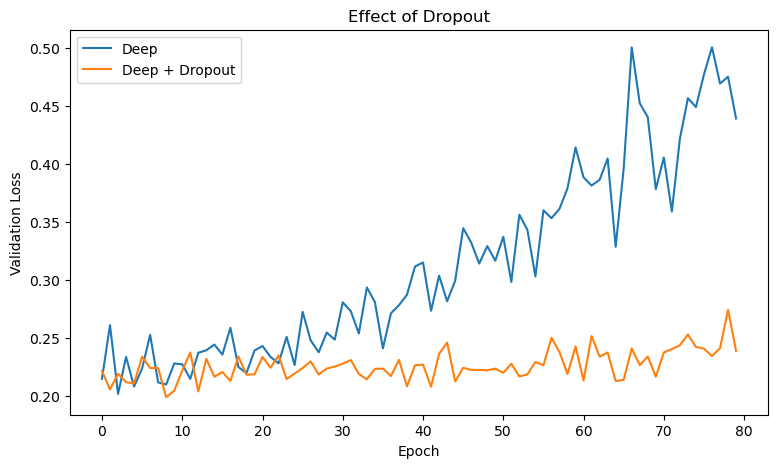

In [47]:
plt.figure(figsize=(9,5))
plt.plot(deep_val_loss, label='Deep')
plt.plot(drop_val_loss, label='Deep + Dropout')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Effect of Dropout')
plt.legend()
plt.show()

# HOW TO READ THIS PLOT:
# Compare validation loss with and without dropout.
# Lower or more stable validation loss can suggest better generalization.


### What to Notice

If dropout produces lower or more stable validation loss, it may be reducing overfitting.

If it performs worse, the original model may not need that amount of regularization, or the dropout rate may be too strong.

## Interpretation

Dropout is not guaranteed to improve every dataset.

The important question is whether regularization improves validation behavior enough to justify using it.

# 15. Learning-Rate Experiment

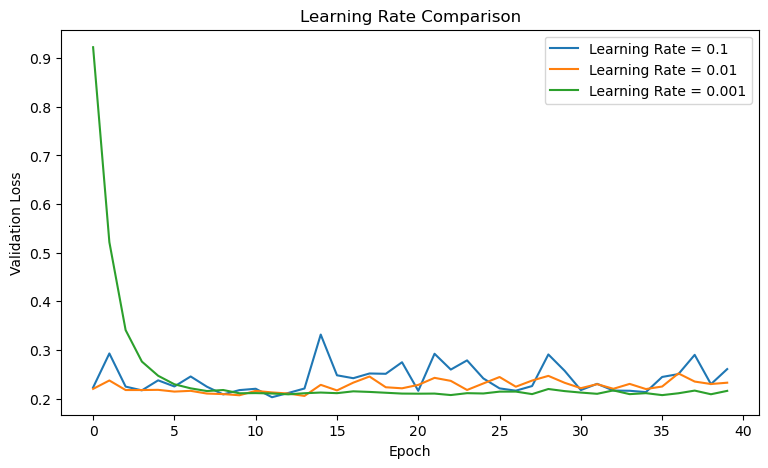

In [48]:
# ===============================================================
# LEARNING-RATE EXPERIMENT
# ===============================================================
#
# We compare three orders of magnitude:
#
#   0.1   -> relatively large
#   0.01  -> medium / our starting value
#   0.001 -> relatively small
#
# Why these values?
# They are intentionally spaced by factors of 10 so the effect is easier
# for students to see.
#
# We keep the architecture fixed (MediumNet) so learning rate is the
# primary thing changing.
# ===============================================================

learning_rates = [
    0.1,
    0.01,
    0.001
]

lr_histories = {}


for lr in learning_rates:

    # Start each experiment from reproducible initialization.
    torch.manual_seed(
        RANDOM_STATE
    )

    temp_model = MediumNet()


    # Why only 40 epochs here instead of 80?
    #
    # This is a quick sensitivity experiment rather than final training.
    # Forty epochs are enough to show whether learning is:
    #   - unstable,
    #   - reasonably fast,
    #   - or very slow.
    _, temp_val_loss = train_model(
        temp_model,
        train_loader,
        X_val_t,
        y_val_t,
        epochs=40,
        learning_rate=lr
    )

    lr_histories[lr] = temp_val_loss


# ---------------------------------------------------------------
# PLOT THE THREE VALIDATION-LOSS PATHS
# ---------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

for lr, history in lr_histories.items():

    plt.plot(
        history,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Validation Loss"
)

plt.title(
    "Learning Rate Comparison"
)

plt.legend()
plt.show()

### Learning Rate Intuition

Think of optimization as moving downhill on a loss surface.

- **Very large step:** you may jump past a good region repeatedly.
- **Very small step:** you move safely but may require many epochs.
- **Reasonable step:** you make meaningful progress without excessive instability.

This is why learning rate often has a major effect on DNN training even when the network architecture is unchanged.

### How to Read the Learning-Rate Curves

A very large learning rate may cause unstable or oscillating loss. A very small learning rate may reduce loss slowly.

The goal is not simply the smallest learning rate; it is a value that learns efficiently and stably.

## Pause and Think

- Did the largest learning rate behave smoothly?
- Did the smallest learning rate improve slowly?
- Which value learned efficiently without becoming unstable?

# 16. Inspect a Confusion Matrix

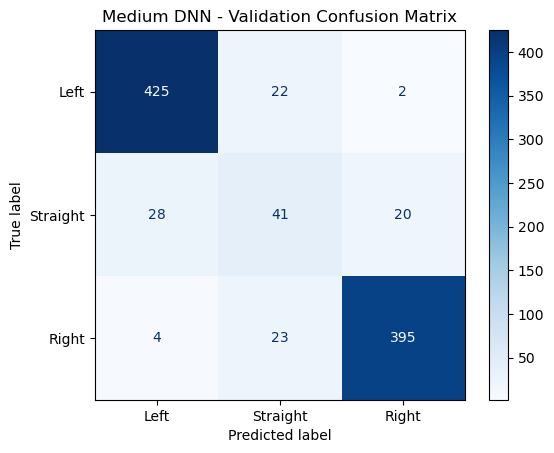

In [49]:
# ---------------------------------------------------------------
# CONFUSION MATRIX
#
# The diagonal shows correct predictions.
# Off-diagonal cells show specific steering mistakes.
# ---------------------------------------------------------------

medium_pred = predictions['Medium']

ConfusionMatrixDisplay.from_predictions(
    y_val,
    medium_pred,
    display_labels=['Left', 'Straight', 'Right'],
    cmap='Blues'
)

plt.title('Medium DNN - Validation Confusion Matrix')
plt.show()

# SELF-DRIVING INTERPRETATION:
# Opposite-direction mistakes may be more serious than a mild
# Left/Straight or Right/Straight confusion.


### How to Read the Confusion Matrix

The diagonal cells are correct predictions. Off-diagonal cells are mistakes.

For autonomous driving, the type of mistake matters. A model that predicts Right when the correct class is Left may be more concerning than a model that predicts Straight for a mild turn.

## Self-Driving Interpretation

Do not look only at overall accuracy.

Ask:
- Does the model miss turns?
- Does it introduce unnecessary turns?
- Does it ever predict the opposite direction?

As we move closer to the simulator project, the **type of error** becomes increasingly important.

# 17. Save a Trained PyTorch Model

In the final project, the simulator should load a trained model rather than retrain it every time it starts.

$$
\text{Train}\rightarrow\text{Save}\rightarrow\text{Load Later}\rightarrow\text{Predict}
$$

In [50]:
# ---------------------------------------------------------------
# SAVE THE TRAINED PARAMETERS
#
# state_dict() stores learned weights and biases.
# This lets us reuse the trained network without retraining it.
# ---------------------------------------------------------------

from pathlib import Path

MODEL_PATH = Path('week9_medium_steering_model.pt')

# state_dict contains learned weights and biases.
torch.save(medium_model.state_dict(), MODEL_PATH)

print('Saved model:', MODEL_PATH)

# FINAL-PROJECT CONNECTION:
# The simulator should load a trained model and use it repeatedly for
# prediction rather than retraining at every time step.


Saved model: week9_medium_steering_model.pt


### Why Saving the Model Matters

Training and deployment are different stages.

The network can be trained once, saved, and later loaded into a simulator-control program. This makes real-time prediction practical.

# 18. Reload the Saved Model

In [51]:
# ---------------------------------------------------------------
# RELOAD THE SAVED NETWORK
#
# First recreate the same architecture, then load its saved parameters.
# ---------------------------------------------------------------

# Recreate the SAME architecture.
loaded_model = MediumNet()

# Load the saved parameters.
loaded_model.load_state_dict(
    torch.load(MODEL_PATH, weights_only=True)
)

loaded_model.eval()

loaded_acc, loaded_f1, loaded_pred = evaluate_model(
    loaded_model, X_val_t, y_val
)

print('Reloaded Accuracy:', round(loaded_acc, 3))
print('Reloaded Macro F1:', round(loaded_f1, 3))

# RESULT INTERPRETATION:
# Reloaded validation metrics should match the original model closely.


Reloaded Accuracy: 0.897
Reloaded Macro F1: 0.783


### Check Your Understanding

If the reloaded model reproduces the original model's validation performance, the learned parameters were successfully restored.

This is an important prerequisite for connecting a trained model to the simulator.

# 19. Why Saving Matters for the Simulator

Eventually, the workflow will be:

$$
\text{Train Model}
\rightarrow
\text{Save Model}
\rightarrow
\text{Launch Simulator}
\rightarrow
\text{Load Model}
\rightarrow
\text{Predict Repeatedly}
$$

The vehicle needs fast predictions, not repeated retraining.

# 20. From Static Prediction to Continuous Control

So far:

$$
\text{One Driving State}\rightarrow\text{One Steering Prediction}
$$

In the simulator:

$$
State_t\rightarrow Action_t\rightarrow State_{t+1}\rightarrow Action_{t+1}\rightarrow\cdots
$$

A prediction changes the vehicle's next state. This is a major difference between ordinary offline prediction and autonomous control.

# 21. Bridge to the Simulator Activity

The second Week 9 activity will introduce the simulator itself.

The full system will eventually look like:

$$
\text{Simulator Observation}
\rightarrow
\text{Model}
\rightarrow
\text{Steering / Throttle}
\rightarrow
\text{Simulator}
$$

Later weeks will add camera-image preprocessing, CNN steering prediction, simulator integration, and robustness testing.

# 22. In-Class Simulator Preview

This section is a **preview of the final-project environment**.

Today, you are **not** expected to connect the DNN to the simulator.

The goal is simply to understand:

- what the simulator looks like,
- what the vehicle must control,
- what information a future model may receive,
- and why autonomous driving is more difficult than making one static prediction.

Think of today's activity as:

$$
\text{Human Driver}
\rightarrow
\text{Simulator}
$$

Later in the course, we will move toward:

$$
\text{Camera / State}
\rightarrow
\text{Model}
\rightarrow
\text{Steering + Throttle}
\rightarrow
\text{Simulator}
$$

## 22.1 Manual Driving Activity

Open the Donkey Car Simulator and choose a simple track.

Drive manually for several minutes.

While driving, pay attention to:

1. how sensitive steering feels,
2. how speed changes the difficulty of staying on the road,
3. what visual information you use before entering a curve,
4. how difficult it is to recover after leaving the center of the road,
5. which parts of the track appear easy or difficult.

### Instructor Question

> **What visual information did you personally use to decide when and how much to steer?**

Possible answers may include:

- road curvature,
- lane position,
- upcoming turns,
- vehicle speed,
- current heading,
- recovery position.

These observations will become important when we begin computer vision and CNN-based steering prediction.

## 22.2 From Human Driver to Autonomous Driver

When you drive manually, the loop looks like:

$$
\text{See Road}
\rightarrow
\text{Decide}
\rightarrow
\text{Steer / Accelerate}
\rightarrow
\text{See New Road Position}
$$

An autonomous system must perform the same loop continuously:

$$
Observation_t
\rightarrow
Action_t
\rightarrow
Observation_{t+1}
\rightarrow
Action_{t+1}
\rightarrow
\cdots
$$

This is different from ordinary predictive analytics.

A normal prediction problem might ask:

> What class should this observation receive?

A driving controller must ask repeatedly:

> What should I do **now**, given the result of my previous action?

That feedback loop makes autonomous driving a **dynamic control problem** rather than just a static prediction problem.

## 22.3 What the Model Will Eventually Control

The simulator's action can be simplified conceptually as:

```text
[steering, throttle]
```

For example:

```text
[0.0, 0.5]
```

can be interpreted approximately as:

- steering near 0 → continue roughly straight
- positive throttle → move forward

The exact useful ranges depend on the simulator configuration and should be tested carefully.

For now, the important idea is:

$$
\text{Model Output}
\rightarrow
\text{Vehicle Action}
$$

## 22.4 Optional Python Preview

The code below shows the **conceptual Gymnasium interaction pattern**.

You do not need to memorize it today.

The important functions are:

- `reset()` → start the environment and receive the first observation
- `step(action)` → send an action and receive the next observation

Later, a trained model will generate the action instead of us typing it manually.

In [52]:
# OPTIONAL PREVIEW ONLY
#
# This cell requires the Donkey Car Simulator and gym-donkeycar
# to be installed and configured correctly.
#
# If your simulator is not set up yet, simply read the code.

# import gymnasium as gym
# import gym_donkeycar
# import numpy as np

# Create a simulator environment.
# env = gym.make("donkey-generated-track-v0")

# Start a new episode.
# obs, info = env.reset()

# Example action:
# [steering, throttle]
# action = np.array([0.0, 0.5])

# Send the action to the simulator.
# obs, reward, terminated, truncated, info = env.step(action)

# Close the simulator connection.
# env.close()

### How to Read the Optional Code

`obs`

represents the new observation returned by the simulator. In later weeks, this may include the camera image used for steering prediction.

`action`

contains the control command sent to the vehicle.

`env.step(action)`

means:

> Apply this steering/throttle command, move the simulator forward one step, and return the new state.

This creates the repeated control loop:

$$
\text{Observe}
\rightarrow
\text{Predict}
\rightarrow
\text{Act}
\rightarrow
\text{Observe Again}
$$

## 22.5 Why Offline Accuracy Is Not Enough

Suppose a steering model has excellent validation accuracy.

That still does **not** guarantee that the vehicle will drive successfully.

Why?

A small steering error can change the vehicle's position.

That new position changes the next camera image.

The next prediction may therefore become harder.

Errors can accumulate over time.

For example:

```text
Small steering error
        ↓
Vehicle moves slightly off-center
        ↓
Next camera view is different
        ↓
Next prediction becomes harder
        ↓
Vehicle moves farther off-center
```

This is why the final project will eventually emphasize:

- route completion,
- robustness,
- recovery,
- smoothness,
- and repeated performance,

rather than relying only on one offline metric.

## 22.6 In-Class Discussion

After manually driving the simulator, discuss:

1. What was the most difficult part of controlling the vehicle?
2. Did higher speed make steering more difficult?
3. What visual cues did you use before entering a curve?
4. What happened after a small steering mistake?
5. Why might a model with high offline accuracy still fail in continuous driving?
6. What information should we record when testing an autonomous controller?

### Key Transition

Today:

$$
\text{Human}
\rightarrow
\text{Steering / Throttle}
$$

Later:

$$
\text{CNN / DNN}
\rightarrow
\text{Steering / Throttle}
$$

## 22.7 Connection to the Next Two Weeks

### Week 10

We will begin working more directly with **computer vision**:

- road images,
- image preprocessing,
- cropping,
- resizing,
- augmentation.

### Week 11

We will move toward:

$$
\text{Camera Image}
\rightarrow
\text{CNN}
\rightarrow
\text{Steering Prediction}
$$

The simulator preview today gives you a concrete reason for learning those techniques.

You have now seen the environment that the future model will eventually need to control.

# 23. Week 9 Takeaways

- Deeper networks have more model capacity.
- More capacity can improve learning but also increase overfitting risk.
- Mini-batches allow several weight updates per epoch.
- Batch size controls how many observations are used per update.
- Learning rate controls the size of parameter updates.
- Dropout can reduce over-reliance on individual hidden units.
- Validation evidence should guide architecture selection.
- A trained model can be saved and reloaded without retraining.
- Simulator control turns static prediction into a continuous decision process.

# Reflection Questions

1. What is the main difference between a shallow neural network and a deeper neural network?
2. Why can adding more layers or neurons improve training performance but hurt validation performance?
3. What does **batch size** control, and why do deep neural networks often use mini-batches?
4. What does the **learning rate** control? What can happen if it is too large or too small?
5. What does dropout attempt to accomplish during neural-network training?
6. Based on the architecture comparison, which network would you select and why? Use validation evidence.
7. Why is saving and reloading a trained model important for the final self-driving simulator project?
8. What new challenge appears when we move from independent predictions to continuously controlling a vehicle?